# 01 · Exploratory data analysis

What the cleaned ATP data looks like before any modelling. Everything here is computed live from
`data/raw/` (Jeff Sackmann's ATP data, 1997–2024 main tour, 2010–2024 Challenger and qualifying)
through the same `load_raw()` → `clean()` path the pipeline uses.

Run `python scripts/download_data.py` first. Every figure is followed by its numbers as a table.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tennis.clean import clean
from tennis.dataset import MAIN_TOUR_LEVELS
from tennis.load import load_raw

pd.set_option("display.precision", 1)

# Chart styling: light surface, hairline grid, muted axes, fixed categorical order.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # blue, orange, aqua, yellow (validated, adjacent-safe)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})

raw = load_raw()
matches = clean(raw)
main = matches[matches["tour_level"].isin(MAIN_TOUR_LEVELS)]
print(f"raw rows: {len(raw):,} | cleaned matches: {len(matches):,} | ATP main-tour matches: {len(main):,}")

raw rows: 205,168 | cleaned matches: 196,780 | ATP main-tour matches: 76,604


## 1. Matches per year

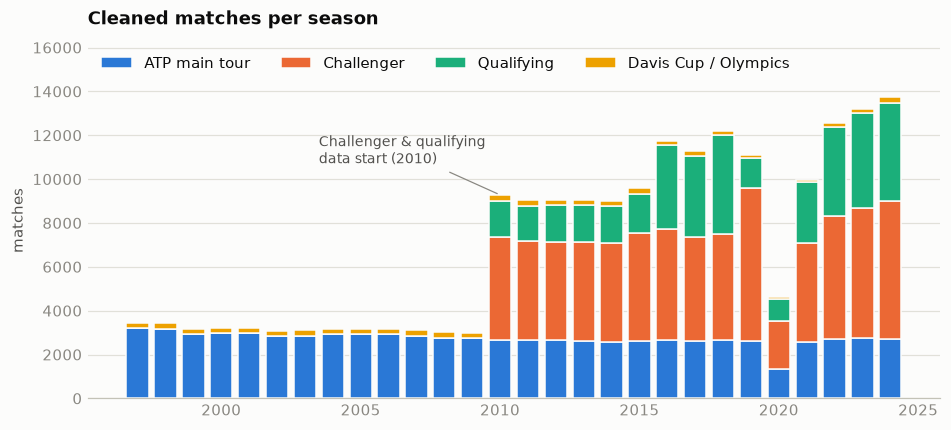

tour_level,ATP main tour,Challenger,Qualifying,Davis Cup / Olympics,Total
year,,,,,
1997,3222,0,0,236,3458
1998,3175,0,0,248,3423
1999,2948,0,0,228,3176
2000,2996,0,0,236,3232
2001,2967,0,0,230,3197
2002,2863,0,0,231,3094
2003,2866,0,0,232,3098
2004,2951,0,0,235,3186
2005,2915,0,0,260,3175


In [2]:
GROUPS = ["ATP main tour", "Challenger", "Qualifying", "Davis Cup / Olympics"]
group = matches["tour_level"].map(lambda l: "ATP main tour" if l in MAIN_TOUR_LEVELS else
                                  "Challenger" if l == "C" else "Qualifying" if l == "Q" else "Davis Cup / Olympics")
per_year = pd.crosstab(matches["year"], group)[GROUPS]

fig, ax = plt.subplots(figsize=(10, 4.2))
bottom = np.zeros(len(per_year))
for name, color in zip(GROUPS, SERIES):
    ax.bar(per_year.index, per_year[name], bottom=bottom, color=color, width=0.8,
           edgecolor=SURFACE, linewidth=1, label=name)
    bottom += per_year[name].to_numpy()
ax.set_title("Cleaned matches per season")
ax.set_ylabel("matches")
ax.grid(axis="x", visible=False)
ax.legend(ncols=4, loc="upper left", bbox_to_anchor=(0, 1.0))
ax.set_ylim(0, bottom.max() * 1.18)
ax.annotate("Challenger & qualifying\ndata start (2010)", xy=(2010, bottom[list(per_year.index).index(2010)]),
            xytext=(2003.5, bottom.max() * 0.78), color=INK_2, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
plt.show()
per_year.assign(Total=per_year.sum(axis=1))

Main-tour volume is steady at roughly 2,600–3,200 matches a season (1,337 in COVID-hit 2020).
From 2010, Challenger and qualifying matches more than triple the yearly history available for
features. That's why the paper and our pipeline include them in training.

## 2. Surface split

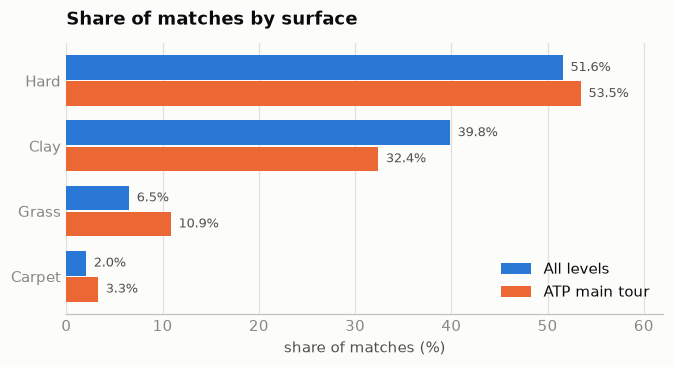

,All levels (%),ATP main tour (%),Matches (all),Matches (main tour)
surface,,,,
Hard,5.2e+01,53.5,101494,40945.0
Clay,4.0e+01,32.4,78414,24818.0
Grass,6.5e+00,10.9,12812,8318.0
Carpet,2.0e+00,3.3,4024,2523.0
Unknown,1.8e-02,0.0,36,0.0


In [3]:
surf = pd.DataFrame({
    "All levels (%)": matches["surface"].value_counts(normalize=True) * 100,
    "ATP main tour (%)": main["surface"].value_counts(normalize=True) * 100,
}).reindex(["Hard", "Clay", "Grass", "Carpet", "Unknown"]).fillna(0)

fig, ax = plt.subplots(figsize=(7, 3.2))
order = ["Hard", "Clay", "Grass", "Carpet"]
y = np.arange(len(order))
h = 0.38
for k, (col, color) in enumerate(zip(surf.columns, SERIES)):
    vals = surf.loc[order, col]
    ax.barh(y + (k - 0.5) * (h + 0.02), vals, height=h, color=color, label=col.replace(" (%)", ""))
    for yi, v in zip(y, vals):
        ax.text(v + 0.8, yi + (k - 0.5) * (h + 0.02), f"{v:.1f}%", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.set_xlim(0, 62)
ax.set_xlabel("share of matches (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Share of matches by surface")
ax.legend(loc="lower right")
plt.show()
surf.assign(**{"Matches (all)": matches["surface"].value_counts(), "Matches (main tour)": main["surface"].value_counts()}).fillna(0)

Hard courts dominate (about half of all matches); clay is the second surface and is heavier at
Challenger level (39.8% overall vs 32.4% on the main tour). Grass is only 10.9% of main-tour matches,
so surface-specific features for grass rest on thin history. Carpet left the main tour after 2008
but stayed in some Challengers until 2023. 36 cleaned matches have an unknown surface.

## 3. Rank baseline by year

Accuracy of always predicting the higher-ranked player, on ATP main-tour matches
(`G`, `M`, `A`, `F`, the same filter as the test set).

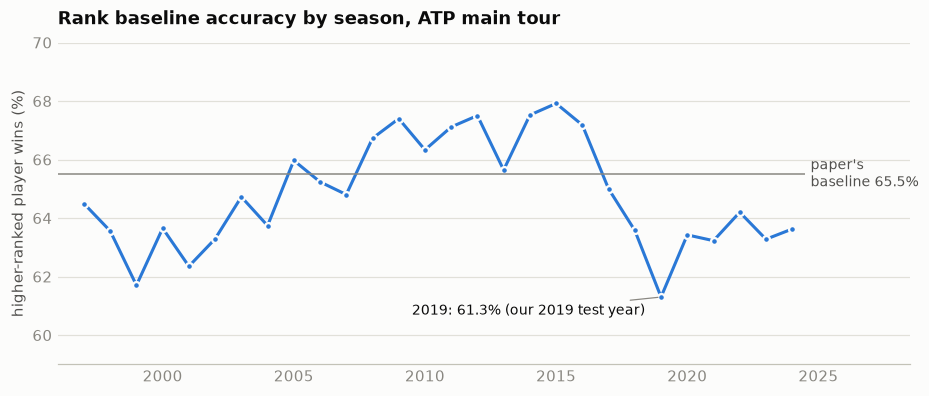

,Matches,Baseline accuracy (%)
year,,
1997,3222,64.5
1998,3175,63.6
1999,2948,61.7
2000,2996,63.7
2001,2967,62.4
2002,2863,63.3
2003,2866,64.7
2004,2951,63.7
2005,2915,66.0


In [4]:
baseline = (main["winner_rank"] < main["loser_rank"]).groupby(main["year"]).mean() * 100

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(baseline.index, baseline.values, color=SERIES[0], lw=2, marker="o", ms=4.5,
        markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.hlines(65.5, 1996, 2024.5, color=MUTED, lw=1)
ax.text(2024.7, 65.5, "paper's\nbaseline 65.5%", color=INK_2, fontsize=9, va="center")
ax.set_xlim(1996, 2028.5)
lo = baseline.idxmin()
ax.annotate(f"{lo}: {baseline[lo]:.1f}% (our 2019 test year)", xy=(lo, baseline[lo]),
            xytext=(lo - 9.5, baseline[lo] - 0.6), color=INK, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_ylim(59, 70)
ax.set_ylabel("higher-ranked player wins (%)")
ax.set_title("Rank baseline accuracy by season, ATP main tour")
ax.grid(axis="x", visible=False)
plt.show()
pd.DataFrame({"Matches": main.groupby("year").size(), "Baseline accuracy (%)": baseline})

The baseline ranges from 61.3% (2019, the lowest season in the data) to 67.9% (2015), with a
mean of 64.8%. The paper's 65.5% fits 2005–2017 well, but our 2019 test season is unusually
hard for rankings. Model results should therefore be compared with our own 2019 baseline,
not with the paper's number.

## 4. Upset rate by rank gap

An upset is the lower-ranked player (higher rank number) winning. ATP main tour, all seasons.

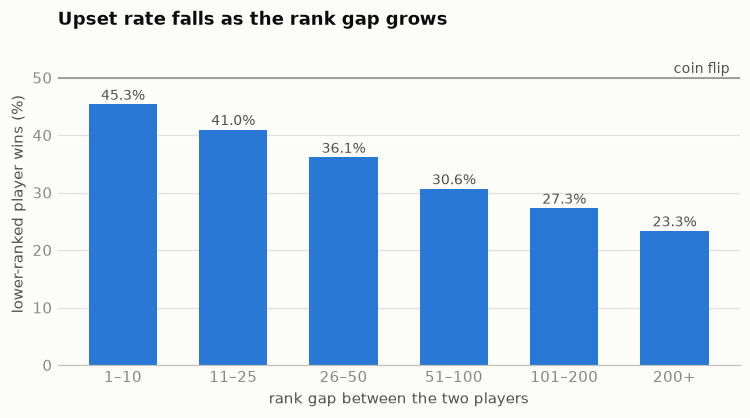

,Matches,Upset rate (%)
gap_bin,,
1–10,10976,45.3
11–25,14671,41.0
26–50,19006,36.1
51–100,18106,30.6
101–200,8764,27.3
200+,5081,23.3


In [5]:
gap = (main["winner_rank"] - main["loser_rank"]).abs()
bins = pd.cut(gap, [0, 10, 25, 50, 100, 200, np.inf], labels=["1–10", "11–25", "26–50", "51–100", "101–200", "200+"])
upsets = (main.assign(upset=main["winner_rank"] > main["loser_rank"], gap_bin=bins)
              .groupby("gap_bin", observed=True)
              .agg(Matches=("upset", "size"), **{"Upset rate (%)": ("upset", "mean")}))
upsets["Upset rate (%)"] *= 100

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(upsets))
ax.bar(x, upsets["Upset rate (%)"], color=SERIES[0], width=0.62)
for xi, v in zip(x, upsets["Upset rate (%)"]):
    ax.text(xi, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9, color=INK_2)
ax.axhline(50, color=MUTED, lw=1)
ax.text(len(x) - 0.5, 50.8, "coin flip", ha="right", color=INK_2, fontsize=9)
ax.set_xticks(x, upsets.index)
ax.set_xlabel("rank gap between the two players")
ax.set_ylabel("lower-ranked player wins (%)")
ax.set_ylim(0, 56)
ax.grid(axis="x", visible=False)
ax.set_title("Upset rate falls as the rank gap grows")
plt.show()
upsets

Even with a gap of 200+ places, the lower-ranked player wins 23.3% of the time. Between players
within 10 places it's 45.3%, close to a coin flip. Rank carries real signal but leaves a lot
unexplained, which is the room the form, head-to-head, serve and Elo features try to fill.

## 5. Missing values

Percentage of player-match values that are missing, in the raw files and after cleaning.
Player attributes are pooled over winner and loser; "hand (unknown)" counts codes other than R/L.

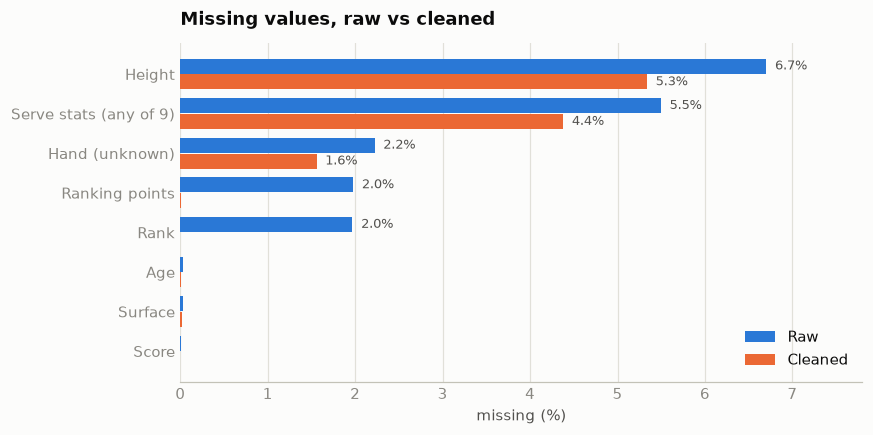

,Raw (%),Cleaned (%)
Height,6.7e+00,5.3e+00
Serve stats (any of 9),5.5e+00,4.4e+00
Hand (unknown),2.2e+00,1.6e+00
Ranking points,2.0e+00,1.0e-02
Rank,2.0e+00,0.0e+00
Age,3.0e-02,0.0e+00
Surface,3.0e-02,2.0e-02
Score,1.0e-02,0.0e+00


In [6]:
STATS = ["svpt", "1stIn", "1stWon", "2ndWon", "ace", "df", "SvGms", "bpSaved", "bpFaced"]

def missing_rates(d):
    both = lambda col: pd.concat([d[f"winner_{col}"], d[f"loser_{col}"]])
    hand = both("hand")
    serve = pd.concat([d[[f"w_{s}" for s in STATS]].isna().any(axis=1),
                       d[[f"l_{s}" for s in STATS]].isna().any(axis=1)])
    surface = d["surface"].isna() | (d["surface"] == "Unknown")
    return pd.Series({
        "Rank": both("rank").isna().mean(), "Ranking points": both("rank_points").isna().mean(),
        "Height": both("ht").isna().mean(), "Hand (unknown)": (~hand.isin(["R", "L"])).mean(),
        "Age": both("age").isna().mean(), "Serve stats (any of 9)": serve.mean(),
        "Surface": surface.mean(), "Score": d["score"].isna().mean(),
    }) * 100

missing = pd.DataFrame({"Raw (%)": missing_rates(raw), "Cleaned (%)": missing_rates(matches)})
missing = missing.sort_values("Raw (%)", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(missing))
h = 0.38
for k, (col, color) in enumerate(zip(missing.columns, SERIES)):
    vals = missing[col]
    ax.barh(y + (k - 0.5) * (h + 0.02), vals, height=h, color=color, label=col.replace(" (%)", ""))
    for yi, v in zip(y, vals):
        if v >= 0.5:
            ax.text(v + 0.1, yi + (k - 0.5) * (h + 0.02), f"{v:.1f}%", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(y, missing.index)
ax.invert_yaxis()
ax.set_xlabel("missing (%)")
ax.set_xlim(0, 7.8)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Missing values, raw vs cleaned")
plt.show()
missing.round(2)

Height is the most often missing attribute (6.7% raw, 5.3% after cleaning), followed by serve
stats (5.5% raw, 4.4% cleaned). Cleaning removes every missing rank by design, because rank is
required, plus the score-less rows. What remains is handled in the pipeline:
- Height, hand, age and ranking points are filled with the training-set median and flagged in
  `*_missing` columns.
- Matches without full serve stats are left out of the serve averages, and `has_serve_stats`
  flags players with no usable history.